# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [3]:
class base:
    SILENT = 6
    DEBUG = 1
    INFO = 2
    WARNING = 3
    ERROR = 4
    CRITICAL = 5

    def __init__(self, level=0):
        self.level = level

    def message(self, level, *args):
        if level >= self.level:
            print(*args)

In [4]:
class Card(base):
    __suits = ["Clubs", "Diamonds", "Hearts", "Spades", "ShuffleCard"]
    __values = list(range(2, 11)) + ["Jack", "Queen", "King", "Ace"]

    def __init__(self, suit, value=None):
        base.__init__(self)

        self.__suit = suit if suit in self.__suits else None
        self.__value = value if value in self.__values else None

        if self.__suit is None:
            self.message(self.ERROR, "Error, bad suit:", suit)

        if self.__value is None and self.__suit != "ShuffleCard":
            self.message(self.ERROR, "Error, bad value:", value)

    def value(self):
        return self.__value

    def suit(self):
        return self.__suit

    def numerical_value(self):
        if self.__value == "Ace":
            return 1
        elif self.__value in ["Jack", "Queen", "King"]:
            return 10
        else:
            return self.__value

    def shuffle_card(self):
        return self.__suit == "ShuffleCard"

    def __str__(self):
        if self.shuffle_card():
            return "Shuffle Card"
        return str(self.__value) + " of " + self.__suit

    __repr__ = __str__

In [5]:
import random

class Deck(base):
    __suits = ["Clubs", "Diamonds", "Hearts", "Spades"]
    __values = list(range(2, 11)) + ["Jack", "Queen", "King", "Ace"]

    def __init__(self, n_decks=6):
        base.__init__(self)

        self.__n_decks = n_decks
        self.__cards = []

        for _ in range(self.__n_decks):
            self.__cards.extend(self.__make_deck())

        # Insert the plastic card at a random position.
        plastic_position = random.randint(0, len(self.__cards))
        self.__cards.insert(plastic_position, Card("ShuffleCard"))

    def __make_deck(self):
        deck = []

        for suit in self.__suits:
            for value in self.__values:
                deck.append(Card(suit, value))

        return deck

    def shuffle(self):
        random.shuffle(self.__cards)

    def deal(self):
        if len(self.__cards) == 0:
            # Rebuild the deck if all cards have been dealt.
            for _ in range(self.__n_decks):
                self.__cards.extend(self.__make_deck())

            self.__cards.append(Card("ShuffleCard"))
            self.shuffle()

        return self.__cards.pop()

2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [6]:
class base:
    SILENT = 6
    DEBUG = 1
    INFO = 2
    WARNING = 3
    ERROR = 4
    CRITICAL = 5

    def __init__(self, level=0):
        self.level = level

    def message(self, level, *args):
        pass


class Card(base):
    __suits = ["Clubs", "Diamonds", "Hearts", "Spades", "ShuffleCard"]
    __values = list(range(2, 11)) + ["Jack", "Queen", "King", "Ace"]

    def __init__(self, suit, value=None):
        super().__init__()
        self.__suit = None
        self.__value = None

    def value(self):
        pass

    def suit(self):
        pass

    def numerical_value(self):
        pass

    def shuffle_card(self):
        pass

    def __str__(self):
        pass

    __repr__ = __str__


class Deck(base):
    __suits = ["Clubs", "Diamonds", "Hearts", "Spades"]
    __values = list(range(2, 11)) + ["Jack", "Queen", "King", "Ace"]

    def __init__(self, n_decks=6):
        super().__init__()
        self.__n_decks = n_decks
        self.__cards = []

    def __make_deck(self):
        pass

    def shuffle(self):
        pass

    def deal(self):
        pass


class PlayerBase(base):
    def __init__(self, name, n_chips):
        super().__init__()
        self.__name = name
        self.__n_chips = n_chips

    def name(self):
        pass

    def chips(self):
        pass

    def pay(self, value=2):
        pass

    def deduct(self, value=2):
        pass

    def play_hand(self, down_card, up_cards, seen_cards):
        pass

    def __str__(self):
        pass

    __repr__ = __str__


class DealerPlayer(PlayerBase):
    def __init__(self, threshold=16):
        super().__init__("Mr. Dealer", 1000)
        self.__threshold = threshold

    def play_hand(self, down_card, up_cards, seen_cards):
        pass


class ConsolePlayer(PlayerBase):
    def play_hand(self, down_card, up_cards, seen_cards):
        pass


class Strategy_1_Player(PlayerBase):
    def play_hand(self, down_card, up_cards, seen_cards):
        pass


class Strategy_2_Player(PlayerBase):
    def play_hand(self, down_card, up_cards, seen_cards):
        pass


class DealerLikePlayer(PlayerBase):
    def __init__(self, name, chips, threshold=16):
        super().__init__(name, chips)
        self.__threshold = threshold

    def play_hand(self, down_card, up_cards, seen_cards):
        pass


class Game(base):
    def __init__(self, n_decks=6):
        super().__init__(self.INFO)
        self.__n_decks = n_decks
        self.__players = []
        self.__all_players = []
        self.__shuffle = False

    def players(self):
        pass

    def all_players(self):
        pass

    def add_player(self, player):
        pass

    def deal_and_check_shuffle(self, deck):
        pass

    def show_status(self, hands, seen_cards):
        pass

    def play_game(self, n_hands):
        pass

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [20]:
import random


class base:
    SILENT = 6
    DEBUG = 1
    INFO = 2
    WARNING = 3
    ERROR = 4
    CRITICAL = 5

    def __init__(self, level=0):
        self.level = level

    def message(self, level, *args):
        if level >= self.level:
            print(*args)


class Card(base):
    __suits = ["Clubs", "Diamonds", "Hearts", "Spades", "ShuffleCard"]
    __values = list(range(2, 11)) + ["Jack", "Queen", "King", "Ace"]

    def __init__(self, suit, value=None):
        super().__init__()
        self.__suit = suit if suit in self.__suits else None
        self.__value = (
            value if value in self.__values
            else None
        )

        if self.__suit is None:
            self.message(self.ERROR, "Error, bad suit:", suit)

        if self.__value is None and self.__suit != "ShuffleCard":
            self.message(self.ERROR, "Error, bad value:", value)

    def value(self):
        return self.__value

    def suit(self):
        return self.__suit

    def numerical_value(self):
        if self.__value == "Ace":
            return 1
        elif self.__value in ["Jack", "Queen", "King"]:
            return 10
        return self.__value

    def shuffle_card(self):
        return self.__suit == "ShuffleCard"

    def __str__(self):
        if self.shuffle_card():
            return "Shuffle Card"
        return str(self.__value) + " of " + self.__suit

    __repr__ = __str__

class Deck(base):
    __suits = ["Clubs", "Diamonds", "Hearts", "Spades"]
    __values = list(range(2, 11)) + ["Jack", "Queen", "King", "Ace"]

    def __init__(self, n_decks=6):
        super().__init__()
        self.__n_decks = n_decks
        self.__cards = []

        for _ in range(self.__n_decks):
            self.__cards.extend(self.__make_deck())

        self.__cards.insert(
            random.randint(0, len(self.__cards)),
            Card("ShuffleCard")
        )

    def __make_deck(self):
        deck = []
        for suit in self.__suits:
            for value in self.__values:
                deck.append(Card(suit, value))
        return deck

    def shuffle(self):
        random.shuffle(self.__cards)

    def deal(self):
        if len(self.__cards) == 0:
            for _ in range(self.__n_decks):
                self.__cards.extend(self.__make_deck())
            self.__cards.append(Card("ShuffleCard"))
            self.shuffle()

        return self.__cards.pop()

In [21]:
def calc_hand_value(hand):
        total = 0
        aces = 0
        
        for card in hand:
          value = card.numerical_value()

          if value == 1:  # Ace
            aces += 1
            total += 11
          else:
            total += value

    # Count Aces as 1 instead of 11 if needed.
        while total > 21 and aces > 0:
          total -= 10
          aces -= 1
        return total

In [22]:
class PlayerBase(base):
    def __init__(self, name, n_chips):
        super().__init__()
        self.__name = name
        self.__n_chips = n_chips

    def name(self):
        return self.__name

    def chips(self):
        return self.__n_chips

    def pay(self, value=2):
        self.__n_chips += value

    def deduct(self, value=2):
        self.__n_chips = max(0, self.__n_chips - value)

    def play_hand(self, down_card, up_cards, seen_cards):
        raise NotImplementedError

    def __str__(self):
        return self.__name + "(" + str(self.__n_chips) + ")"

    __repr__ = __str__

class DealerPlayer(PlayerBase):
    def __init__(self, name="Mr. Dealer", n_chips=1000, threshold=16):
        super().__init__(name, n_chips)
        self.__threshold = threshold

    def play_hand(self, down_card, up_cards, seen_cards):
        hand_value = calc_hand_value([down_card] + up_cards)
        return hand_value < self.__threshold

class ConsolePlayer(PlayerBase):
    def play_hand(self, down_card, up_cards, seen_cards):
        print("Down Card:", down_card)
        print("Up Cards:", up_cards)
        print("Seen Cards:", seen_cards)

        while True:
            hit_str = input("Hit (Y/N): ").strip().upper()

            if hit_str in ("Y", "N"):
                return hit_str == "Y"

            print("Please enter Y to hit or N to stay.")

class Game(base):
    def __init__(self, n_decks=6):
        super().__init__(self.INFO)
        self.__n_decks = n_decks
        self.__players = []
        self.__all_players = []
        self.__shuffle = False

    def players(self):
        return self.__players

    def all_players(self):
        return self.__all_players

    def add_player(self, player):
        self.__players.append(player)
        self.__all_players.append(player)

    def deal_and_check_shuffle(self, deck):
        card = deck.deal()

        if card.shuffle_card():
            self.__shuffle = True
            return self.deal_and_check_shuffle(deck)

        return card

    def show_status(self, hands, seen_cards):
        self.message(self.INFO, "-" * 50)
        self.message(self.INFO, "Hands:", hands)
        self.message(self.INFO, "Seen cards:", seen_cards)
        self.message(self.INFO, "Players:")

        for i, player in enumerate(self.__all_players):
            self.message(self.INFO, i, player)

    def play_game(self, n_hands):
        dealer = DealerPlayer()
        self.add_player(dealer)

        deck = Deck(self.__n_decks)
        deck.shuffle()

        for hand_number in range(n_hands):
            # Remove players who cannot afford the minimum bet.
            self.__players = [
                p for p in self.__players
                if p is dealer or p.chips() >= 2
            ]

            if self.__shuffle:
                deck = Deck(self.__n_decks)
                deck.shuffle()
                self.__shuffle = False

            if len(self.__players) <= 1:
                self.message(self.INFO, "No active players remain.")
                break

            seen_cards = []
            hands = []

            # Deal one face-down card to each player.
            for player in self.__players:
                down_card = self.deal_and_check_shuffle(deck)
                hands.append([down_card, []])

            # Deal one face-up card to each player.
            for i, player in enumerate(self.__players):
                up_card = self.deal_and_check_shuffle(deck)
                hands[i][1].append(up_card)
                seen_cards.append(up_card)

            # Players take turns hitting or staying.
            for i, player in enumerate(self.__players):
                down_card, up_cards = hands[i]

                # The dealer's hole card stays hidden until the dealer's turn.
                visible_seen = list(seen_cards)

                while True:
                    hand_value = calc_hand_value([down_card] + up_cards)

                    if hand_value >= 21:
                        break

                    hit = player.play_hand(
                        down_card, up_cards, visible_seen
                    )

                    if not hit:
                        break

                    card = self.deal_and_check_shuffle(deck)
                    up_cards.append(card)
                    seen_cards.append(card)
                    visible_seen.append(card)

            # Reveal the dealer's down card.
            dealer_index = self.__players.index(dealer)
            dealer_down, dealer_up = hands[dealer_index]
            seen_cards.append(dealer_down)

            # Dealer follows the fixed threshold rule.
            while calc_hand_value([dealer_down] + dealer_up) < 16:
                card = self.deal_and_check_shuffle(deck)
                dealer_up.append(card)
                seen_cards.append(card)

            dealer_value = calc_hand_value([dealer_down] + dealer_up)

            # Settle bets for all non-dealer players.
            for i, player in enumerate(self.__players):
                if player is dealer:
                    continue

                player_value = calc_hand_value(
                    [hands[i][0]] + hands[i][1]
                )

                if player_value > 21:
                    player.deduct(2)
                elif dealer_value > 21:
                    player.pay(2)
                elif player_value > dealer_value:
                    player.pay(2)
                elif player_value < dealer_value:
                    player.deduct(2)

            self.message(self.INFO, "Hand:", hand_number + 1)
            self.show_status(hands, seen_cards)

            # The plastic card triggers a shuffle before the next hand.
            if self.__shuffle:
                deck = Deck(self.__n_decks)
                deck.shuffle()
                self.__shuffle = False

        self.__players = [
            player for player in self.__players if player is not dealer
        ]

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [23]:
my_game = Game(n_decks=6)

my_game.add_player(DealerPlayer("Player 1", 100))
my_game.add_player(DealerPlayer("Player 2", 100))
my_game.add_player(DealerPlayer("Player 3", 100))
my_game.add_player(DealerPlayer("Player 4", 100))

print("Starting Player Balances:")
for player in my_game.players():
    print(player)

my_game.play_game(5)

print("\nFinal Player Balances:")
for player in my_game.all_players():
    print(player)

Starting Player Balances:
Player 1(100)
Player 2(100)
Player 3(100)
Player 4(100)
Hand: 1
--------------------------------------------------
Hands: [[6 of Clubs, [King of Clubs]], [Queen of Hearts, [3 of Hearts, 10 of Diamonds]], [King of Spades, [3 of Spades, Jack of Diamonds]], [Jack of Hearts, [9 of Hearts]], [4 of Clubs, [7 of Clubs, 4 of Hearts, Ace of Hearts]]]
Seen cards: [King of Clubs, 3 of Hearts, 3 of Spades, 9 of Hearts, 7 of Clubs, 10 of Diamonds, Jack of Diamonds, 4 of Hearts, Ace of Hearts, 4 of Clubs]
Players:
0 Player 1(100)
1 Player 2(98)
2 Player 3(98)
3 Player 4(102)
4 Mr. Dealer(1000)
Hand: 2
--------------------------------------------------
Hands: [[8 of Hearts, [2 of Diamonds, 7 of Clubs]], [7 of Hearts, [Jack of Spades]], [2 of Spades, [Jack of Diamonds, 7 of Hearts]], [3 of Diamonds, [10 of Spades, 8 of Clubs]], [6 of Spades, [Queen of Clubs]]]
Seen cards: [2 of Diamonds, Jack of Spades, Jack of Diamonds, 10 of Spades, Queen of Clubs, 7 of Clubs, 7 of Hearts, 

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [24]:
class Strategy_2_Player(PlayerBase):
    def __init__(self, name="Strategy 2", n_chips=100, threshold=0):
        super().__init__(name, n_chips)
        self.__threshold = threshold

    def play_hand(self, down_card, up_cards, seen_cards):
        count = 0

        for card in seen_cards:
            if card.shuffle_card():
                continue

            value = card.numerical_value()

            if 2 <= value <= 6:
                count += 1
            elif value in [7, 8, 9]:
                count += 0
            else:
                count -= 1

        hand_value = calc_hand_value([down_card] + up_cards)

        if hand_value >= 21:
            return False

        return count < self.__threshold

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [25]:
# Create a game with six decks
my_game = Game(n_decks=6)

# Give every player the same starting balance
starting_chips = 100

# One card-counting strategy player
strategy_player = Strategy_2_Player(
    "Strategy Player",
    starting_chips,
    threshold=0
)
my_game.add_player(strategy_player)

# Three players following the dealer's strategy
my_game.add_player(DealerPlayer("Player 1", starting_chips))
my_game.add_player(DealerPlayer("Player 2", starting_chips))
my_game.add_player(DealerPlayer("Player 3", starting_chips))

# Turn off routine game output
my_game.level = Game.SILENT

# Play up to 50 rounds
my_game.play_game(50)

# Calculate and display the strategy player's winnings
final_chips = strategy_player.chips()
winnings = final_chips - starting_chips

print("Rounds requested: 50")
print("Starting chips:", starting_chips)
print("Final chips:", final_chips)
print("Strategy player's winnings:", winnings)

if final_chips == 0:
    print("The strategy player ran out of money.")
else:
    print("The strategy player still has chips.")

Rounds requested: 50
Starting chips: 100
Final chips: 58
Strategy player's winnings: -42
The strategy player still has chips.


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Number of games: 100
Rounds per game: 50
Average net winnings: -40.98
Average winnings per round: -0.8196
Standard deviation of net winnings: 12.03
Probability of winning: 0.0 %
Probability of losing: 100.0 %
Probability of breaking even: 0.0 %


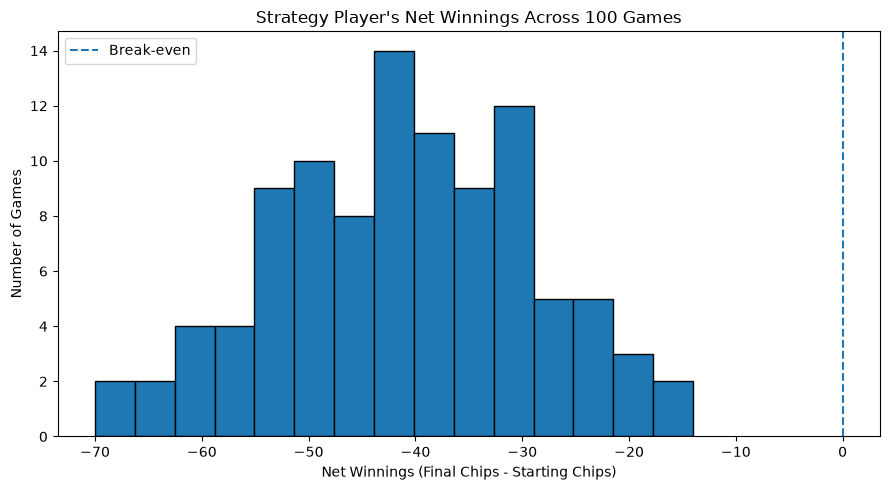

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
n_games = 100
n_rounds = 50
starting_chips = 100

# Store net winnings from each game
winnings = []
final_chip_balances = []

for game_number in range(n_games):
    # Create a fresh game for each simulation
    my_game = Game(n_decks=6)

    # Add one card-counting strategy player
    strategy_player = Strategy_2_Player(
        "Strategy Player",
        starting_chips,
        threshold=0
    )
    my_game.add_player(strategy_player)

    # Add three players following the dealer's strategy
    my_game.add_player(DealerPlayer("Player 1", starting_chips))
    my_game.add_player(DealerPlayer("Player 2", starting_chips))
    my_game.add_player(DealerPlayer("Player 3", starting_chips))

    # Suppress routine game output
    my_game.level = Game.SILENT

    # Play up to 50 rounds
    my_game.play_game(n_rounds)

    # Record the final balance and net winnings
    final_chips = strategy_player.chips()
    final_chip_balances.append(final_chips)
    winnings.append(final_chips - starting_chips)

# Convert to a NumPy array
winnings = np.array(winnings)

# Calculate statistics
average_winnings = np.mean(winnings)
std_winnings = np.std(winnings, ddof=1)
average_per_round = average_winnings / n_rounds

prob_win = np.mean(winnings > 0)
prob_loss = np.mean(winnings < 0)
prob_break_even = np.mean(winnings == 0)

# Display results
print("Number of games:", n_games)
print("Rounds per game:", n_rounds)
print("Average net winnings:", round(average_winnings, 2))
print("Average winnings per round:", round(average_per_round, 4))
print("Standard deviation of net winnings:", round(std_winnings, 2))
print("Probability of winning:", round(prob_win * 100, 2), "%")
print("Probability of losing:", round(prob_loss * 100, 2), "%")
print("Probability of breaking even:", round(prob_break_even * 100, 2), "%")

# Plot histogram
plt.figure(figsize=(9, 5))
plt.hist(winnings, bins=15, edgecolor="black")
plt.axvline(0, linestyle="--", label="Break-even")
plt.xlabel("Net Winnings (Final Chips - Starting Chips)")
plt.ylabel("Number of Games")
plt.title("Strategy Player's Net Winnings Across 100 Games")
plt.legend()
plt.tight_layout()
plt.show()

9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

 Threshold  Average Net Winnings  Average Winnings per Round  Standard Deviation  Win Probability (%)  Loss Probability (%)  Break-even Probability (%)
        -5                -25.14                       -0.50               13.11                  3.0                  97.0                         0.0
        -2                -30.94                       -0.62               14.11                  2.0                  98.0                         0.0
        -1                -33.82                       -0.68               11.83                  0.0                 100.0                         0.0
         0                -41.20                       -0.82               12.26                  0.0                 100.0                         0.0
         1                -48.46                       -0.97               11.10                  0.0                 100.0                         0.0
         2                -55.30                       -1.11               11.72        

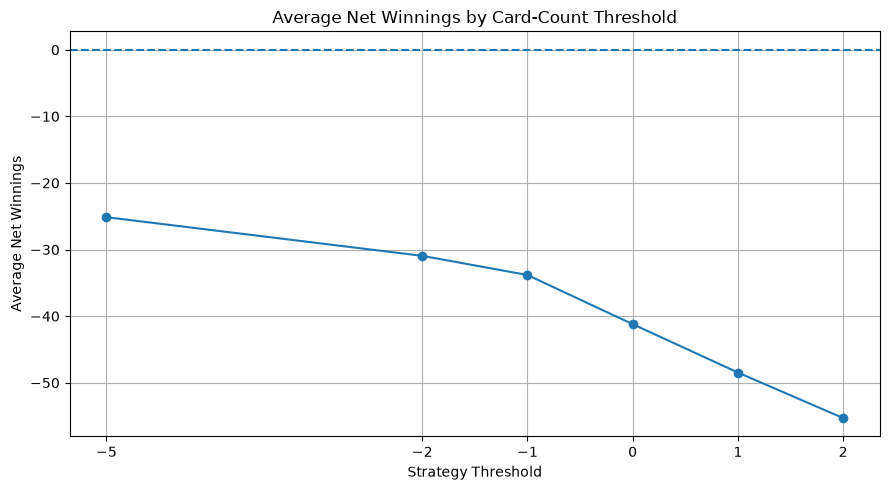

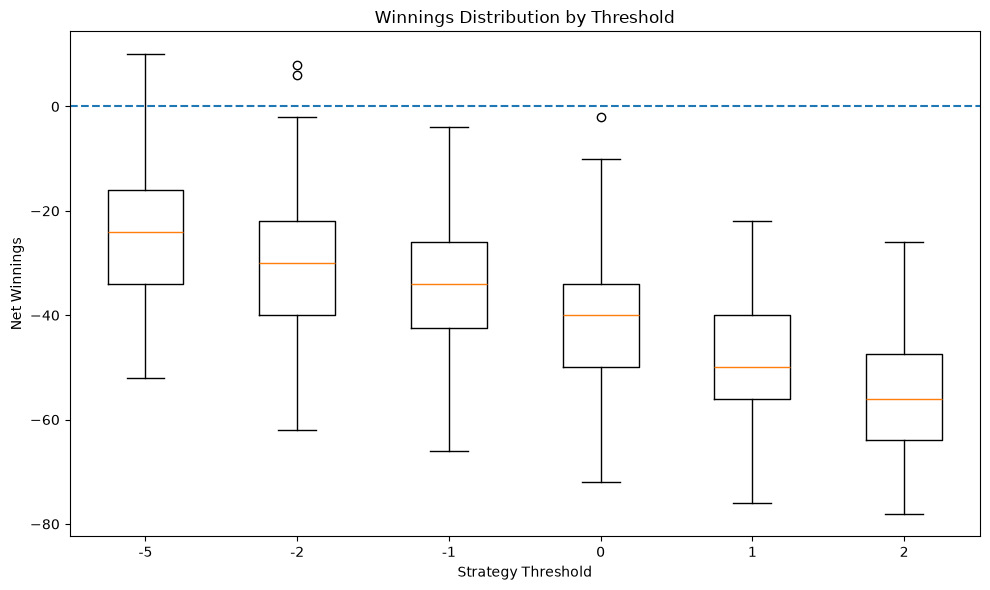

In [28]:
import pandas as pd

# Simulation settings
thresholds = [-5, -2, -1, 0, 1, 2]
n_games = 100
n_rounds = 50
starting_chips = 100

results = []
all_winnings = {}

for threshold in thresholds:
    winnings = []

    for game_number in range(n_games):
        my_game = Game(n_decks=6)

        # Strategy player uses the current threshold
        strategy_player = Strategy_2_Player(
            "Strategy Player",
            starting_chips,
            threshold=threshold
        )
        my_game.add_player(strategy_player)

        # Three dealer-strategy opponents
        my_game.add_player(DealerPlayer("Player 1", starting_chips))
        my_game.add_player(DealerPlayer("Player 2", starting_chips))
        my_game.add_player(DealerPlayer("Player 3", starting_chips))

        # Suppress normal game output
        my_game.level = Game.SILENT

        my_game.play_game(n_rounds)

        # Net winnings, not just final chip balance
        winnings.append(strategy_player.chips() - starting_chips)

    winnings = np.array(winnings)
    all_winnings[threshold] = winnings

    results.append({
        "Threshold": threshold,
        "Average Net Winnings": np.mean(winnings),
        "Average Winnings per Round": np.mean(winnings) / n_rounds,
        "Standard Deviation": np.std(winnings, ddof=1),
        "Win Probability (%)": np.mean(winnings > 0) * 100,
        "Loss Probability (%)": np.mean(winnings < 0) * 100,
        "Break-even Probability (%)": np.mean(winnings == 0) * 100
    })

results_df = pd.DataFrame(results)

print(results_df.round(2).to_string(index=False))

# Plot average net winnings by threshold
plt.figure(figsize=(9, 5))
plt.plot(
    results_df["Threshold"],
    results_df["Average Net Winnings"],
    marker="o"
)
plt.axhline(0, linestyle="--")
plt.xlabel("Strategy Threshold")
plt.ylabel("Average Net Winnings")
plt.title("Average Net Winnings by Card-Count Threshold")
plt.xticks(thresholds)
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot distributions for each threshold
plt.figure(figsize=(10, 6))
plt.boxplot(
    [all_winnings[t] for t in thresholds],
    tick_labels=[str(t) for t in thresholds]
)
plt.axhline(0, linestyle="--")
plt.xlabel("Strategy Threshold")
plt.ylabel("Net Winnings")
plt.title("Winnings Distribution by Threshold")
plt.tight_layout()
plt.show()

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [29]:
class Strategy_3_Player(PlayerBase):
    def __init__(self, name="Hand Total Strategy", n_chips=100):
        super().__init__(name, n_chips)

    def play_hand(self, down_card, up_cards, seen_cards):
        hand_value = calc_hand_value([down_card] + up_cards)

        if hand_value <= 11:
            return True
        elif hand_value >= 17:
            return False
        else:
            return True

       Strategy  Average Net Winnings  Standard Deviation  Win Probability (%)  Loss Probability (%)
Card Count (-5)                -25.74               15.72                  4.0                  95.0
     Hand Total                 -5.12               13.10                 35.0                  60.0


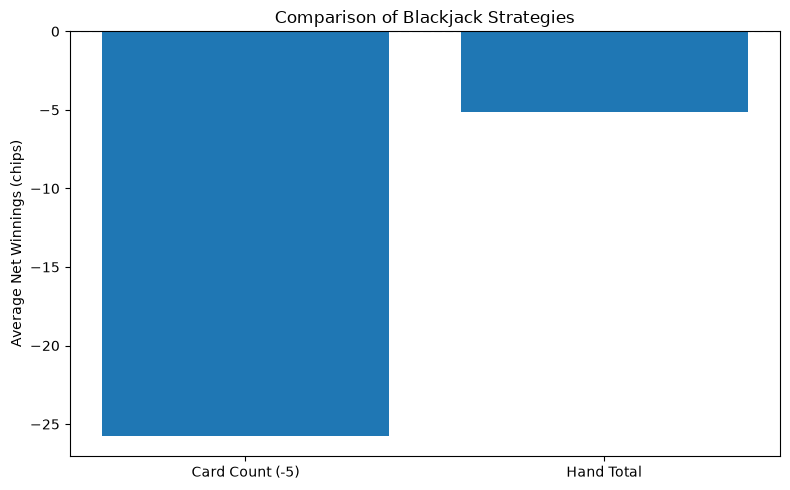

In [30]:
n_games = 100
n_rounds = 50
starting_chips = 100

strategies = {
    "Card Count (-5)": lambda: Strategy_2_Player(
        "Strategy Player", starting_chips, threshold=-5
    ),
    "Hand Total": lambda: Strategy_3_Player(
        "Strategy Player", starting_chips
    )
}

results = []

for strategy_name, make_player in strategies.items():
    winnings = []

    for _ in range(n_games):
        game = Game(n_decks=6)
        player = make_player()
        game.add_player(player)

        game.add_player(DealerPlayer("Player 1", starting_chips))
        game.add_player(DealerPlayer("Player 2", starting_chips))
        game.add_player(DealerPlayer("Player 3", starting_chips))

        game.level = Game.SILENT
        game.play_game(n_rounds)

        winnings.append(player.chips() - starting_chips)

    results.append({
        "Strategy": strategy_name,
        "Average Net Winnings": np.mean(winnings),
        "Standard Deviation": np.std(winnings, ddof=1),
        "Win Probability (%)": np.mean(np.array(winnings) > 0) * 100,
        "Loss Probability (%)": np.mean(np.array(winnings) < 0) * 100
    })

results_df = pd.DataFrame(results)
print(results_df.round(2).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.bar(results_df["Strategy"], results_df["Average Net Winnings"])
plt.axhline(0, linestyle="--")
plt.ylabel("Average Net Winnings (chips)")
plt.title("Comparison of Blackjack Strategies")
plt.tight_layout()
plt.show()